In [1]:
# Imports
import sys, time, math, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

sys.path.insert(0, str(Path.cwd().parent))

from common.utils import set_seed, get_device, count_parameters
from common.datasets import (FASHION_MNIST_CLASSES, FASHION_MNIST_SHAPE, 
                             load_fashion_mnist, load_or_create_split,
                             pixel_stats, to_tensor_dataset,
                             make_train_loader, make_eval_loaders)
from common.training import fit
from common.evaluation import collect_outputs, evaluate_model, format_results_table
from common.plotting import setup_style, save_fig, plot_learning_curves, plot_confusion_matrices
from E1.config import CONFIG, SPLIT_PATH, NUM_CLASSES

set_seed(CONFIG["seed"])
DEVICE = get_device()

E3_CONFIG = dict(
  hidden_size=128,
  num_layers=1,
  bidirectional=False,
  dropout=0.1,
  pool="last",
  head="softmax",
  batch_first=True
)

RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
setup_style()

In [2]:
# load data
train_images, train_labels, test_images, test_labels = load_fashion_mnist(CONFIG["data_dir"])
train_idx, val_idx = load_or_create_split(train_labels, SPLIT_PATH, CONFIG["seed"], CONFIG["val_ratio"])
X_train, y_train = train_images[train_idx], train_labels[train_idx]
X_val, y_val = train_images[val_idx], train_labels[val_idx]
X_test, y_test = test_images, test_labels
mean, std = pixel_stats(X_train)
datasets = {
    "train": to_tensor_dataset(X_train, y_train, mean, std),
    "val": to_tensor_dataset(X_val, y_val, mean, std),
    "test": to_tensor_dataset(X_test, y_test, mean, std),
}

train_loader = make_train_loader(datasets["train"], CONFIG["batch_size"], CONFIG["seed"])
eval_loaders = make_eval_loaders(datasets, CONFIG["batch_size"])

## RNN

Tập dữ liệu là Fashion-MNIST sẽ có dạng [B, 1, 28, 28], tương ứng với **[B, C, H, W]**.
Trong bài toán LSTM hoặc GRU, cần đưa về dạng: **[B, T, D]**, với:
  - **T** là số bước thời gian, RNN nói chung xử lý tuần tự từng bước: t=0, 1, ... T-1
  - **D** là số chiều của vector đưa vào ở mỗi bước (`input_size` của LSTM).



### Các cách để đưa ảnh thành chuỗi

#### Row-by-row

- Một bước thời gian là một hàng pixel, đọc từ trên xuống dưới.
- Trong đó, [B, T, D] có dạng [B, 28, 28]
- Xét trên tập dữ liệu Fashion-MNIST: hình dạng quần áo thay đổi rõ theo chiều dọc: như từ cổ áo -> tay áo -> thân...

#### Column-by-column

- Một bước thời gian là một cột pixel, đọc từ trái sang phải.
- Trong đó, [B, T, D] có dạng [B, 28, 28]
- Xét trên dataset, giống với row nhưng khác hướng quét, đây dược xem là thí nghiệm có kiểm soát.

#### Patching 7x7

- Một bước thời gian là một patch 7x7 (tương tự như patch 7x7 đã làm ở E2), sẽ chia ảnh thành lưới 4x4 (vì ảnh có kích thước 28x28), đọc từ trái sang phải và từ trên xuống dưới.
- [B, T, D] có dạng [B, 16, 49]

In [3]:
def create_sequence(x: torch.Tensor, mode: str = "row", patch_size: int = 7) -> torch.Tensor:
    """
    Biến ảnh [B, C, H, W] thành chuỗi [B, T, D]

    Args:
        mode (str): row | col | patch

    Note:
        B: batch size
        C: number of channels
        H: height of the image
        W: width of the image
        T: sequence length
        D: feature dimension
    """
    assert mode in ["row", "col", "patch"], f"Invalid mode: {mode}, must be one of ['row', 'col', 'patch']"
    B, C, H, W = x.shape

    if mode == "row":
        # mỗi hàng từ trên xuống dưới trở thành một bước trong chuỗi
        # T = H
        # D = C * W
        return x.permute(0, 2, 1, 3).reshape(B, H, C * W)

    if mode == "col":
        # mỗi cột từ trái sang phải trở thành một bước trong chuỗi
        # T = W
        # D = C * H
        return x.permute(0, 3, 1, 2).reshape(B, W, C * H)

    if mode == "patch":
        # chia ảnh thành các patch kích thước patch_size x patch_size
        # T = số lượng patch = (H // patch_size) * (W // patch_size)
        # D = C * patch_size * patch_size
        # ví dụ patch_size = 7, ảnh 28x28
        # T = (28 // 7) * (28 // 7) = 4 x 4 = 16
        # D = C * 7 * 7 = 49 (vì C = 1)
        p = patch_size
        assert H % p == 0 and W % p == 0, "H and W must be divisible by patch_size"
        x = x.reshape(B, C, H // p, p, W // p, p).permute(0, 2, 4, 1, 3, 5)
        return x.reshape(B, (H // p) * (W // p), C * p * p)

def sequence_shape(spec, image_shape=FASHION_MNIST_SHAPE):
    T, D = create_sequence(torch.zeros(1, *image_shape), **spec).shape[1:]
    return T, D

SEQUENCES = {
    "row": dict(mode="row"),
    "col": dict(mode="col"),
    "patch": dict(mode="patch", patch_size=7),
}

In [4]:
# Test - shape và số pixel
xb, yb = next(iter(train_loader))
print(f"{'sequence':<10}{'input':<20}{'output':<20}{'T':>5}{'D':>5}")
for name, spec in SEQUENCES.items():
    seq = create_sequence(xb, **spec)
    T, D = sequence_shape(spec)
    assert seq.shape == (xb.size(0), T, D)
    assert T * D == np.prod(FASHION_MNIST_SHAPE), "Số pixel phải được giữ nguyên"
    print(f"{name:<10}{str(tuple(xb.shape)):<20}{str(tuple(seq.shape)):<20}{T:>5}{D:>5}")

sequence  input               output                  T    D
row       (128, 1, 28, 28)    (128, 28, 28)          28   28
col       (128, 1, 28, 28)    (128, 28, 28)          28   28
patch     (128, 1, 28, 28)    (128, 16, 49)          16   49


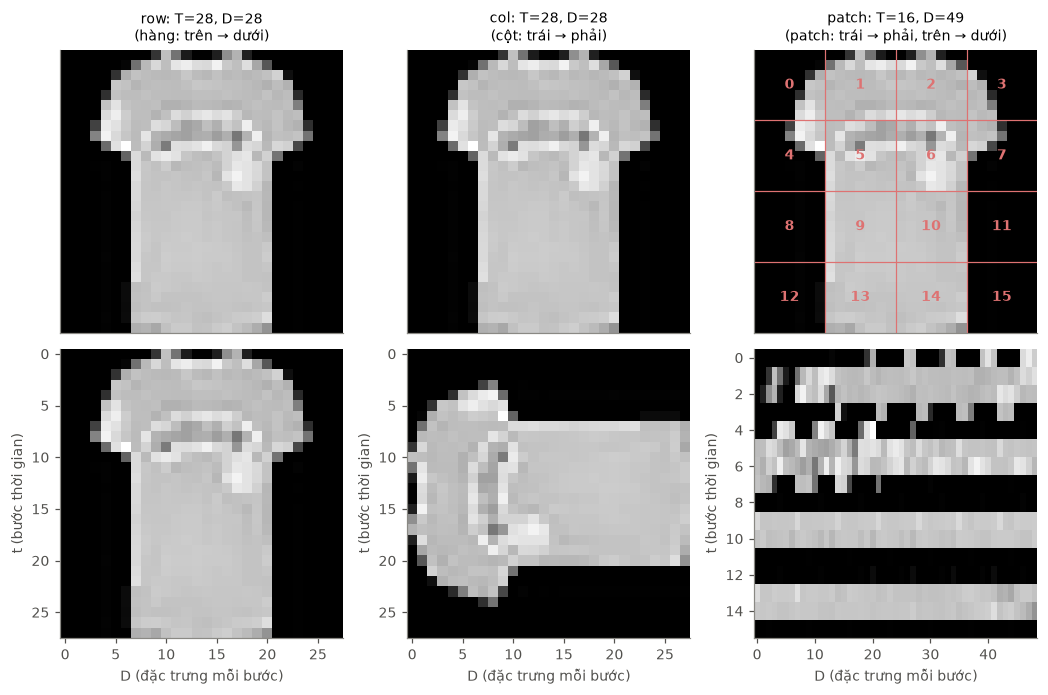

PosixPath('figures/E3_sequences.png')

In [5]:
# Minh họa 3 cách biểu diễn
SCAN_ORDER = {"row": "hàng: trên → dưới", "col": "cột: trái → phải", "patch": "patch: trái → phải, trên → dưới"}

def plot_sequences(image, sequences=SEQUENCES):
    """Hàng trên: ảnh và thứ tự quét; hàng dưới: chuỗi [T, D] mà RNN thực sự nhận vào."""
    fig, axes = plt.subplots(2, len(sequences), figsize=(3.2 * len(sequences), 6.4))
    for k, (name, spec) in enumerate(sequences.items()):
        seq = create_sequence(image[None], **spec)[0]   # [1, C, H, W] -> [T, D]
        T, D = seq.shape

        ax = axes[0, k]
        ax.imshow(image[0], cmap="gray")
        if spec["mode"] == "patch":                     # vẽ lưới patch và số thứ tự bước t
            p = spec["patch_size"]
            g = image.shape[-1] // p
            for i in range(1, g):
                ax.axhline(i * p - 0.5, color="#DE7272", lw=0.8)
                ax.axvline(i * p - 0.5, color="#DE7272", lw=0.8)
            for t in range(T):
                r, c = divmod(t, g)
                ax.text(c * p + (p - 1) / 2, r * p + (p - 1) / 2, str(t), color="#DE7272",
                        ha="center", va="center", fontsize=9, fontweight="bold")
        ax.set_title(f"{name}: T={T}, D={D}\n({SCAN_ORDER[spec['mode']]})", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])

        ax = axes[1, k]
        ax.imshow(seq.numpy(), cmap="gray", aspect="auto")
        ax.set(xlabel="D (đặc trưng mỗi bước)", ylabel="t (bước thời gian)")
    fig.tight_layout()
    return fig

i = int(np.flatnonzero(y_test == 0)[0])                 # ảnh T-shirt đầu tiên của tập test
save_fig(plot_sequences(datasets["test"].tensors[0][i]), FIG_DIR, "E3_sequences", show=True)

- **Hàng trên**: ảnh gốc
- **Hàng dưới**: đúng ma trận [T, D] mà RNN nhận, mỗi hàng ngang là input `x_t` ở bước $t$.
- **Row-by-row**: ma trận giống hệt ảnh gốc do quét từ trên xuống dưới.
- **Col-to-col**: ma trận là ảnh bị chuyển vị, ở bước t, RNN thấy cả cột t nên tay áo bên trái sẽ xuất hiện đầu tiên (nằm ở trên) và tay áo bên phải nằm xuất hiện sau (nằm ở dưới theo thứ tự bước thời gian).
- **Patch**: có khoảng 6~8/16 bước gần như toàn màu đen. Đó là các patch nền ở góc và viền, như các bước 0, 3, 4, 7, 8, 11, 12, 15.

  - Ở các bước này, RNN gần như không nhận được thông tin mới, nhưng vẫn phải giữ trạng thái đã tích lũy qua chúng.
  - Row và Col cũng có hiện tượng tương tự ở vài hàng/cột đầu và cuối.
  - Đây chính là bài toán "nhớ qua nhiều bước" mà cổng của LSTM/GRU được thiết kế.

## LSTM / GRU

```
           **********************************
Input  --> *   LSTM / GRU  --> h_T [B, H]   * --> Dropout -> Linear -> logits [B, 10]
           **********************************
     X
[B,1,28,28]
    ⬇ create_sequence
  [B,T,D]
```

Trong RNN:
$$
\begin{aligned}
\mathbf{h}_t &= \text{tanh}(\mathbf{W}_{xh} \mathbf{X}_{t} + \mathbf{W}_{hh} \mathbf{h}_{t-1} + \mathbf{b}_{t}) \\
\mathbf{z}_t &= \mathbf{W}_{hy} \mathbf{h}_{t} + \mathbf{b}_{y}
\end{aligned}
$$

Trong LSTM:
$$
\begin{aligned}
\mathbf{c}_{t} &= \mathbf{f}_{t} \odot \mathbf{c}_{t-1} + \mathbf{i}_{t} \odot \mathbf{g}_{t} \\
\mathbf{h}_{t} &= \mathbf{o}_{t} \odot \text{tanh}(\mathbf{c}_{t}) \\
\mathbf{f}_{t} &= \sigma (\mathbf{W}_{f} \mathbf{z}_{t} + \mathbf{b}_{f}) \\
\mathbf{o}_{t} &= \sigma (\mathbf{W}_{o} \mathbf{z}_{t} + \mathbf{b}_{o}) \\
\mathbf{i}_{t} &= \sigma (\mathbf{W}_{i} \mathbf{z}_{t} + \mathbf{b}_{i}) \\ 
\mathbf{g}_{t} &= \text{tanh}(\mathbf{W}_{g} \mathbf{z}_{t} + \mathbf{b}_{g}) \\
\end{aligned}
$$

hay nói cách khác, LSTM nhận thêm một "băng chuyền" `c_t` và 4 cổng:
- i, f, o = sigma(·) và g = tanh(·)   # input, forget, output gates; g = nội dung mới
- c_t = f (·) c_t-1 + i (·) g         # cộng dồn, không nhân ma trận
- h_t = o (·) tanh(c_t)

  - `c_t` được cập nhật bằng phép cộng, có điều chỉnh bởi `f`.
  - khi f≈1, gradient đi ngược qua c gần như không bị suy giảm -> đây là cơ chế "nhớ qua nhiều bước"

Trong GRU: có 3 khối reset `r`, update `z` và new `n`, không có `c` riêng. Do vậy `z` đóng cả vai trò cổng forget lẫn cỗng input.

$$\mathbf{h}_{t} = (1 - \mathbf{z}) \odot n + \mathbf{z} \odot \mathbf{h}_{t-1}$$

Trong Pytorch, với batch_first=true thì:
- `nn.LSTM` trả về `out, (h_n, c_n)`. Còn `nn.GRU` trả về `out, h_n`.
- `out` có shape [B, T, dirs·H]: hidden state ở mọi bước, chỉ của tầng trên cùng.
- `h_n` có shape [layers·dirs, B, H]: hidden state ở bước cuối, của mọi tầng.

In [6]:
from E1.classifiers import SoftmaxClassifier, MLPClassifier


RNNS = {
    "lstm": nn.LSTM,
    "gru": nn.GRU,
}

class RNNClassifier(nn.Module):
    """Ảnh [B, C, H, W] -> chuỗi [B, T, D] -> LSTM/GRU -> vector đặc trưng -> logits [B, 10]"""
    def __init__(self, rnn_type="lstm", seq_spec=SEQUENCES["row"], 
                 hidden_size=128, num_layers=1, bidirectional=False, dropout=0.1, 
                 pool="last", head="softmax", batch_first=True):
        super().__init__()
        assert rnn_type.lower() in ["lstm", "gru"], "rnn_type must be either 'lstm' or 'gru'"
        self.seq_spec = dict(seq_spec)
        self.num_steps, input_size = sequence_shape(seq_spec) # T, D
        self.pool = pool
        self.num_directions = 2 if bidirectional else 1
        self.rnn = RNNS[rnn_type.lower()](
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0,
            batch_first=batch_first
        )
        feat_dim = hidden_size * self.num_directions
        self.drop = nn.Dropout(dropout)
        if head == "softmax":
            self.head = SoftmaxClassifier(input_dim=feat_dim, num_classes=NUM_CLASSES)
        else:
            self.head = MLPClassifier(input_dim=feat_dim, hidden_dims=(feat_dim,), dropout=dropout, num_classes=NUM_CLASSES)

    def forward(self, x):
        # Tạo chuỗi từ ảnh với "spec" được cung cấp ở trên
        seq = create_sequence(x, **self.seq_spec)
        out, h_n = self.rnn(seq)  # out: [B, T, D*num_directions], 
                                  # h: [num_layers*num_directions, B, D]
        if isinstance(h_n, tuple):  # LSTM trả về (h_n, c_n)
            h_n = h_n[0]

        if self.pool == "last":
            # hidden state cuối của tầng trên cùng, ghép 2 chiều nếu bidirectional
            feat = torch.cat(list(h_n[-self.num_directions:]), dim=-1) # [B, D * H]
        else:
            # pooling theo mean
            feat = out.mean(dim=1)  # [B, D * H]

        feat = self.drop(feat)
        logits = self.head(feat)
        return logits

    @torch.no_grad()
    def predict_proba(self, x):
        self.eval()
        return torch.softmax(self(x), dim=1)

def build_model(rnn_type, seq_name, **overrides):
    cfg = {**E3_CONFIG, **overrides}
    return RNNClassifier(
        rnn_type=rnn_type,
        seq_spec=SEQUENCES[seq_name],
        **cfg
    )

In [7]:
# Test 1 — shape và số tham số
def rnn_param_formula(rnn_type, D, H):
    gates = {"lstm": 4, "gru": 3}[rnn_type]
    return gates * (D * H + H * H + 2 * H)  # công thức tính số tham số RNN theo lý thuyết

H = E3_CONFIG["hidden_size"]
x = torch.randn(8, 1, 28, 28)
print(f"{'model':<12}{'T':>4}{'D':>4}{'rnn':>9}{'head':>7}{'total':>9}")
for rnn_type in RNNS:
    for seq_name in SEQUENCES:
        set_seed(0)
        model = build_model(rnn_type, seq_name)
        assert model(x).shape == (8, NUM_CLASSES), "Output shape is incorrect"
        T, D = sequence_shape(SEQUENCES[seq_name])
        n_rnn = count_parameters(model.rnn)
        assert n_rnn == rnn_param_formula(rnn_type, D, H), "Số tham số RNN không khớp công thức"
        print(f"{rnn_type + '_' + seq_name:<12}{T:>4}{D:>4}{n_rnn:>9,}{count_parameters(model.head):>7,}"
              f"{count_parameters(model):>9,}")

model          T   D      rnn   head    total
lstm_row      28  28   80,896  1,290   82,186
lstm_col      28  28   80,896  1,290   82,186
lstm_patch    16  49   91,648  1,290   92,938
gru_row       28  28   60,672  1,290   61,962
gru_col       28  28   60,672  1,290   61,962
gru_patch     16  49   68,736  1,290   70,026


- LSTM có 4 cổng: input, forget, cell, output. Số tham số là 4·(D·H + H·H + 2H)
- GRU có 3 cổng: reset, update, new. Số tham số là 3·(D·H + H·H + 2H)
- Vì vậy, với cùng H, GRU luôn có đúng 3/4 tham số của LSTM.

So sánh với kết quả ở bảng trên:
- Bảng trên được in ra tức là `count_parameter` của model khớp với công thức tính tay.
- Số tham số của GRU ở các cách tokenizer đều bằng 3/4 so với LSTM.

In [8]:
from E1.classifiers import MODELS as E1_MODELS
from E2.experiment import ResultStore
from E2.timing import measure_latency

def train_and_evaluate(name, make_model, seed=CONFIG["seed"]):
    """Vòng chung cho mọi model: tạo model -> fit -> evaluate -> outputs trên test."""
    set_seed(seed)
    model = make_model()

    train_loader = make_train_loader(datasets["train"], CONFIG["batch_size"], seed)
    t0 = time.perf_counter()
    history, best_epoch = fit(
        model=model,
        train_loader=train_loader,
        val_loader=eval_loaders["val"],
        epochs=CONFIG["epochs"],
        lr=CONFIG["lr"],
        weight_decay=CONFIG["weight_decay"],
        seed=seed,
        patience=CONFIG["patience"],
        device=DEVICE,
    )

    t1 = time.perf_counter()
    history["train_time"] = t1 - t0

    row = evaluate_model(
        model=model,
        name=name,
        best_epoch=best_epoch,
        train_time=history["train_time"],
        eval_loaders=eval_loaders,
        device=DEVICE,
    )

    row.update(
        epochs_run=len(history["val_acc"]),
        sec_per_epoch=float(np.mean(history["epoch_time"])),
        latency_ms=measure_latency(model),
    )

    outputs = collect_outputs(
        model=model,
        dataloader=eval_loaders["test"],
        device=DEVICE,
    )
    
    return row, history, outputs, model

def run_experiment(rnn_type, seq_name, seed=CONFIG["seed"]):
    name = f"{rnn_type}_{seq_name}"
    row, history, outputs, model = train_and_evaluate(name, lambda: build_model(rnn_type, seq_name), seed)
    T, D = sequence_shape(SEQUENCES[seq_name])
    row.update(
        rnn_type=rnn_type,
        sequence=seq_name,
        num_step=T,
        input_size=D,
    )
    return row, history, outputs, model

def run_baseline(name, seed=CONFIG["seed"]):
    row, history, outputs, model = train_and_evaluate(name, lambda: E1_MODELS[name](), seed)
    row.update(
        rnn_type="baseline",
        sequence="image",
        num_step=1,
        input_size=int(np.prod(FASHION_MNIST_SHAPE)),
    )
    return row, history, outputs, model

In [9]:
store = ResultStore(RESULTS_DIR)
for rnn_type in RNNS:
    for seq_name in SEQUENCES:
        name = f"{rnn_type}_{seq_name}"
        if name in store.done:
            print(f"Đã chạy {name}")
            continue
        
        print(f"Chạy {name}")
        row, history, outputs, model = run_experiment(rnn_type, seq_name)
        store.record(name, row, history, outputs, model)

store.load_outputs()
results, histories, outputs = store.results, store.histories, store.outputs
print(format_results_table(results))

Đã chạy lstm_row
Đã chạy lstm_col
Đã chạy lstm_patch
Đã chạy gru_row
Đã chạy gru_col
Đã chạy gru_patch
Model              Params  Best ep  Time(s)    Train      Val     Test
----------------------------------------------------------------------
lstm_row           82,186       24     54.3   94.43%   90.71%   89.82%
lstm_col           82,186       22     43.5   93.51%   89.87%   89.01%
lstm_patch         92,938       21     34.3   95.28%   89.39%   88.40%
gru_row            61,962       14     65.3   92.73%   90.53%   89.91%
gru_col            61,962       20     81.6   93.79%   90.21%   89.24%
gru_patch          70,026       14     37.7   93.93%   89.42%   88.16%
MLP               535,818       36     36.6   96.57%   90.54%   89.41%
CNN               421,642       12     67.5   96.57%   93.08%   92.24%


In [10]:
print(format_results_table(results))

Model              Params  Best ep  Time(s)    Train      Val     Test
----------------------------------------------------------------------
lstm_row           82,186       24     54.3   94.43%   90.71%   89.82%
lstm_col           82,186       22     43.5   93.51%   89.87%   89.01%
lstm_patch         92,938       21     34.3   95.28%   89.39%   88.40%
gru_row            61,962       14     65.3   92.73%   90.53%   89.91%
gru_col            61,962       20     81.6   93.79%   90.21%   89.24%
gru_patch          70,026       14     37.7   93.93%   89.42%   88.16%
MLP               535,818       36     36.6   96.57%   90.54%   89.41%
CNN               421,642       12     67.5   96.57%   93.08%   92.24%


### Baseline từ E1

In [11]:
BASELINES = ["MLP", "CNN"]
for name in BASELINES:
    if name in store.done:
        print(f"Đã chạy baseline {name}")
        continue

    print(f"Chạy baseline {name}")
    row, history, outputs, model = run_baseline(name)
    store.record(name, row, history, outputs, model)

store.load_outputs()
results, histories, outputs = store.results, store.histories, store.outputs

Đã chạy baseline MLP
Đã chạy baseline CNN


In [12]:
print(format_results_table(results))

Model              Params  Best ep  Time(s)    Train      Val     Test
----------------------------------------------------------------------
lstm_row           82,186       24     54.3   94.43%   90.71%   89.82%
lstm_col           82,186       22     43.5   93.51%   89.87%   89.01%
lstm_patch         92,938       21     34.3   95.28%   89.39%   88.40%
gru_row            61,962       14     65.3   92.73%   90.53%   89.91%
gru_col            61,962       20     81.6   93.79%   90.21%   89.24%
gru_patch          70,026       14     37.7   93.93%   89.42%   88.16%
MLP               535,818       36     36.6   96.57%   90.54%   89.41%
CNN               421,642       12     67.5   96.57%   93.08%   92.24%


In [13]:
# Kiểm tra: train lại có khớp với số đã báo cáo ở E1 không
e1_reported = {r["model"]: r for r in json.loads((Path.cwd().parent / "E1/results/results.json").read_text())}
print(f"{'baseline':<10}{'E1 report':>11}{'E3 retrain':>12}")
for name in BASELINES:
    r = next(r for r in results if r["model"] == name)
    print(f"{name:<10}{e1_reported[name]['test_acc']:>11.2%}{r['test_acc']:>12.2%}")

baseline    E1 report  E3 retrain
MLP            89.62%      89.41%
CNN            92.58%      92.24%


## Evaluation

In [14]:
RNN_NAMES = [f"{r}_{s}" for r in RNNS for s in SEQUENCES]
by_name = {r["model"]: r for r in results}
print(format_results_table([by_name[a] for a in RNN_NAMES + BASELINES]))
print(f"*"*80)
print(f"\n{'model':<12}{'T':>4}{'D':>5}{'epochs':>8}{'s/ep':>7}{'lat(ms)':>9}{'gap':>6}")
for n in RNN_NAMES + BASELINES:
    r = by_name[n]
    print(f"{n:<12}{r['num_step']:>4}{r['input_size']:>5}{r['epochs_run']:>8}"
          f"{r['sec_per_epoch']:>7.1f}{r['latency_ms']:>9.2f}{(r['train_acc'] - r['val_acc']) * 100:>6.1f}")

Model              Params  Best ep  Time(s)    Train      Val     Test
----------------------------------------------------------------------
lstm_row           82,186       24     54.3   94.43%   90.71%   89.82%
lstm_col           82,186       22     43.5   93.51%   89.87%   89.01%
lstm_patch         92,938       21     34.3   95.28%   89.39%   88.40%
gru_row            61,962       14     65.3   92.73%   90.53%   89.91%
gru_col            61,962       20     81.6   93.79%   90.21%   89.24%
gru_patch          70,026       14     37.7   93.93%   89.42%   88.16%
MLP               535,818       36     36.6   96.57%   90.54%   89.41%
CNN               421,642       12     67.5   96.57%   93.08%   92.24%
********************************************************************************

model          T    D  epochs   s/ep  lat(ms)   gap
lstm_row      28   28      29    1.6     0.27   3.7
lstm_col      28   28      27    1.4     0.23   3.6
lstm_patch    16   49      26    1.1     0.15   5.9


#### Theo cách biểu diễn

- row tốt nhất trong ba cách biến ảnh thành chuỗi (row | col | patch), với test_acc là 89.8%~89.9%, col kém hơn khoảng 0.7 điểm, patch thì kém hơn khoảng 1.4~1.7 điểm so với row. Thứ tự này giống nhau ở cả LSTM và GRU.
- row và col có cùng T, D và số tham số tham gia mô hình, nên chênh lệch này giữa chúng đến từ hướng quét. Đọc ảnh từ tren xuống dưới (row) có lợi hơn đọc từ trái sang phải, vì hình dạng quần áo thay đổi theo chiều dọc rõ hơn.

#### LSTM vs GRU

- Accuracy gần như bằng nhau trên mọi cách biểu diễn.
- GRU ít tham số hơn LSTM 1/4 và dừng sớm hơn LSTM.

#### So với Baseline

- LSTM và GRU có accuracy ngang với MLP nhưng dùng ít tham số hơn rất nhiều.
- Tất cả RNN đều kém hơn CNN khoảng 2.4, 2.5 điểm trở lên đến khoảng 4.5 điểm.

#### Thời gian train

- Patch có thời gian train nhanh nhất trong số tất cả, vì chỉ có T=16 bước tuần từ, so với T=28 của row/col.
- Xét về độ trễ (latency), các mô hình RNN rơi vào khoảng 0.14~0.27ms, gần tương đương với CNN 0.13ms, trong khi đó MLP nhanh nhất chỉ với 0.02ms vì chỉ là vài phép nhân ma trận.

#### Gap

- Gap là khoảng cách giữa train và val.
- Trong đó, patch có gap lớn nhất khoảng 5.9 điểm, nên patch overfit nhiều nhất.
- GRU row có gap nhỏ nhất là 2.2
- MLP có gap = 6.0, do nó sử dụng rất nhiều tham số.

In [17]:
# Learning curves
RNN_COLORS = {"lstm": "#2a78d6", "gru": "#F2A900"}
SEQ_COLORS = {"row": "#DE7272", "col": "#55A9A0", "patch": "#8a6fd1"}

for seq_name in SEQUENCES:                                   # LSTM vs GRU trên cùng một cách biểu diễn
    names = [f"{r}_{seq_name}" for r in RNNS]
    fig = plot_learning_curves({n: histories[n] for n in names}, {n: RNN_COLORS[n.split("_")[0]] for n in names})
    fig.suptitle(f"{seq_name}: LSTM vs. GRU", y=1.02)
    save_fig(fig, FIG_DIR, f"E3_curves_{seq_name}_lstm_vs_gru")
    print(f"Đã lưu biểu đồ cho {seq_name} tại: {FIG_DIR}/E3_curves_{seq_name}_lstm_vs_gru.png")

for rnn_type in RNNS:                                        # cùng một RNN, so các cách biểu diễn
    names = {s: f"{rnn_type}_{s}" for s in SEQUENCES}
    fig = plot_learning_curves({s: histories[n] for s, n in names.items()}, SEQ_COLORS)
    fig.suptitle(f"{rnn_type.upper()}: so sánh cách biểu diễn chuỗi", y=1.02)
    save_fig(fig, FIG_DIR, f"E3_curves_{rnn_type}_sequences")
    print(f"Đã lưu biểu đồ cho {rnn_type} tại: {FIG_DIR}/E3_curves_{rnn_type}_sequences.png")

Đã lưu biểu đồ cho row tại: figures/E3_curves_row_lstm_vs_gru.png
Đã lưu biểu đồ cho col tại: figures/E3_curves_col_lstm_vs_gru.png
Đã lưu biểu đồ cho patch tại: figures/E3_curves_patch_lstm_vs_gru.png
Đã lưu biểu đồ cho lstm tại: figures/E3_curves_lstm_sequences.png
Đã lưu biểu đồ cho gru tại: figures/E3_curves_gru_sequences.png


![alt text](figures/E3_curves_row_lstm_vs_gru.png)
![alt text](figures/E3_curves_col_lstm_vs_gru.png)
![alt text](figures/E3_curves_patch_lstm_vs_gru.png)
![alt text](figures/E3_curves_lstm_sequences.png)
![alt text](figures/E3_curves_gru_sequences.png)

In [19]:
# Kiểm định Mcnemar giữa các mô hình

from scipy.stats import binomtest

def mcnemar(outputs, a, b):
    y, p_a, _ = outputs[a]
    _, p_b, _ = outputs[b]
    n_a = int(np.sum((p_a == y) & (p_b != y)))   # a đúng, b sai
    n_b = int(np.sum((p_a != y) & (p_b == y)))   # a sai, b đúng
    pval = binomtest(n_a, n_a + n_b, 0.5).pvalue if n_a + n_b else 1.0
    return (p_a == p_b).mean(), n_a, n_b, pval

best_rnn = max(RNN_NAMES, key=lambda n: by_name[n]["val_acc"])     # chọn theo VAL, không theo test
PAIRS = [(f"lstm_{s}", f"gru_{s}") for s in SEQUENCES] + [(best_rnn, "MLP"), (best_rnn, "CNN")]
print(f"best RNN (theo val acc): {best_rnn}")
print(f"{'A':<12}{'B':<12}{'acc A':>8}{'acc B':>8}{'agree':>8}{'A>B':>6}{'B>A':>6}{'p':>8}")
for a, b in PAIRS:
    agree, n_a, n_b, pval = mcnemar(outputs, a, b)
    print(f"{a:<12}{b:<12}{by_name[a]['val_acc']:>8.2%}{by_name[b]['val_acc']:>8.2%}{agree:>8.2%}{n_a:>6}{n_b:>6}{pval:>8.3f}")

best RNN (theo val acc): lstm_row
A           B              acc A   acc B   agree   A>B   B>A       p
lstm_row    gru_row       90.71%  90.53%  92.75%   308   317   0.749
lstm_col    gru_col       89.87%  90.21%  91.70%   351   374   0.414
lstm_patch  gru_patch     89.39%  89.42%  90.91%   395   371   0.406
lstm_row    MLP           90.71%  90.54%  91.16%   401   360   0.147
lstm_row    CNN           90.71%  93.08%  91.43%   263   505   0.000


#### best_rnn

- Model "tốt nhất" được chọn theo val accuracy, trong đó `lstm_row` có acc đạt 90.71%, `gru_row` chỉ đạt 90.53%.
- Dù trên test thì `gru_row` nhỉnh hơn `lstm_row` với điểm số 89.91% so với 89.82%, tuy nhiên ta không được chọn model theo test, làm vậy là dùng tập test để ra quyết định, trong khi con số test báo cáo sẽ bị lạc quan.

#### Kết luận:

- LSTM và GRU: có p > 0.4 ở cả ba cách biểu diễn, lớn hơn nhiều so với 0.05 (5%), tức là không có khác biệt có ý nghĩa thống kê.
- RNN tốt nhất (`lstm_row`) và MLP: có p≈0.15, chênh lệch 0.17 điểm, chưa đủ kết luận để nói rằng RNN tốt hơn.
- RNN tốt nhất (`lstm_row`) và CNN: có p<0.001, CNN đúng ở 505 ảnh mà RNN sai, trong khi ngược lại RNN chỉ đúng khoảng 263, tức là tỉ lệ CNN đúng gấp đôi RNN đúng. Điều này cho thấy CNN tốt hơn là có ý nghĩa thống kê.

In [20]:
# Confusion matrix, recall và các lỗi tự tin nhất

from common.plotting import plot_misclassified
from E1.report import KEY_PAIRS

cm_names = [best_rnn, "MLP", "CNN"]
fig, cms = plot_confusion_matrices({n: outputs[n] for n in cm_names}, FASHION_MNIST_CLASSES)
save_fig(fig, FIG_DIR, "E3_confusion_matrices")

print(f"{'Recall (%)':<26}" + "".join(f"{n:>12}" for n in cms))
for k, cls_name in enumerate(FASHION_MNIST_CLASSES):
    print(f"{cls_name:<26}" + "".join(f"{cms[n][k, k]:>12.1%}" for n in cms))
for true_name, pred_name in KEY_PAIRS:
    i, j = FASHION_MNIST_CLASSES.index(true_name), FASHION_MNIST_CLASSES.index(pred_name)
    print(f"{true_name + ' -> ' + pred_name:<26}" + "".join(f"{cms[n][i, j]:>12.0%}" for n in cms))

yt, yp, pr = outputs[best_rnn]
save_fig(plot_misclassified(X_test, yt, yp, pr, FASHION_MNIST_CLASSES, best_rnn), FIG_DIR, f"E3_misclassified_{best_rnn}")

Recall (%)                    lstm_row         MLP         CNN
T-shirt/top                      82.6%       84.7%       86.7%
Trouser                          98.5%       98.3%       98.8%
Pullover                         84.7%       75.7%       88.8%
Dress                            89.5%       88.9%       93.9%
Coat                             84.6%       88.1%       88.2%
Sandal                           96.8%       96.9%       98.5%
Shirt                            70.8%       71.2%       73.4%
Sneaker                          97.6%       95.1%       98.1%
Bag                              97.8%       97.8%       98.7%
Ankle boot                       95.3%       97.4%       97.3%
Coat -> Pullover                    7%          4%          5%
Shirt -> T-shirt/top               11%         12%         10%
T-shirt/top -> Shirt               11%         10%          9%
Shirt -> Pullover                   7%          5%          7%
Shirt -> Coat                       7%          8%     

PosixPath('figures/E3_misclassified_lstm_row.png')

![alt text](figures/E3_confusion_matrices.png)
![alt text](figures/E3_misclassified_lstm_row.png)

#### Nhận xét

- RNN (lstm_row) mạnh hơn MLP ở nhận dạng đúng Pullover (85 > 76). Nhưng kém hơn ở nhận dạng Coat (85 < 88) và T-Shirt (83 < 85).
- Trong khi đó, tỉ lệ coat bị nhầm thành pullover là 7%, ở MLP là 4%.
- Tổng accuracy của hai model (RNN_lstm_row và MLP) gần bằng nhau, chúng sai ở những chỗ khác nhau, điều này phản ánh lại kiểm định McNemar: hai model bất đồng ở khoảng 9% ảnh.
- Nhìn chung, thì CNN vẫn là model nhận dạng tốt hơn, có các chỉ số cao đồng đều hơn so với hai mô hình còn lại.
- Shirt vẫn là lớp khó nhất (71–73%) ở mọi model.